In [67]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import TomekLinks

In [70]:
def plot_label_vs_all(X_pca_labelled, labels):
    """
    Function to plot the distribution of labels in a 2D scatter plot.
    
    Parameters:
    X_pca_labelled (DataFrame): The dataset containing the PCA results with 'label', 'PC1', and 'PC2' columns.
    labels (array-like): A list or array of labels to plot separately in red.

    Returns:
    None
    """
    for label in labels:
        plt.figure(figsize=(8, 6))

        # Plot "other" labels in light gray
        other = X_pca_labelled[X_pca_labelled['label'] != label]
        plt.scatter(other['PC1'], other['PC2'], color='lightgray', label='Other', alpha=0.5)

        # Plot the current label in red
        current = X_pca_labelled[X_pca_labelled['label'] == label]
        plt.scatter(current['PC1'], current['PC2'], color='red', label=f'Label {label}', alpha=0.8)

        plt.title(f'PC1 vs PC2: Label {label} vs All')
        plt.xlabel('PC1')
        plt.ylabel('PC2')
        plt.legend()
        plt.tight_layout()
        plt.show()

# Example usage:
# plot_label_vs_all(X_pca_labelled, low_count_labels)

In [71]:
# Setup all data files as df and sql 
X_train = pd.read_csv("../data/X_train.csv")
y_train = pd.read_csv("../data/y_train.csv")

conn = sqlite3.connect(":memory:")

X_train.to_sql("X_train", conn, index=False, if_exists="replace")
y_train.to_sql("y_train", conn, index=False, if_exists="replace")

10000

In [72]:
# Check for null labels (unclassified targets)
query = '''
SELECT 
    COUNT(label) AS null_count
FROM y_train
WHERE label IS NULL;
'''

null_count = pd.read_sql(query, conn)
print(null_count.to_string(index=False))

 null_count
          0


There are labels for each instance in the training dataset.

In [73]:
# Examine label distribution in training data
query = '''
SELECT label, COUNT(*) AS count 
FROM y_train 
GROUP BY label
ORDER BY count DESC'''

label_distribution = pd.read_sql(query, conn)
print(label_distribution.to_string(index=False))

 label  count
     5   4479
    10   1081
     6    553
     8    516
    12    457
    24    385
    17    354
    26    278
    21    269
    14    264
     4    238
    25    184
    19    177
    20    153
    27    107
     7    103
    11     78
     3     65
    13     62
    18     60
    23     41
    15     26
     9     25
     0     18
    22      7
     2      7
     1      7
    16      6


There is an imbalanced distribution of labels.
- Label 5 taking the majoirty of 4479 training instances.
- 12 labels have less than 100 training instances.
- Labels 1, 2, 16, 22 have only 6-7 training instances.

Data Augmentation is one way to deal with class imbalance

- Oversample minority classes
- Undersample majority classes

In [74]:
# Apply PCA (2 dimensions) to better visualise data

# Standardise data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

# Apply PCA
pca = PCA(n_components=2) 
X_pca = pca.fit_transform(X_scaled)

X_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
X_pca.to_sql("X_pca", conn, index=False, if_exists="replace")

10000

In [1]:
new_pca = PCA(n_components=0.95)  # Keep enough components to explain 95% variance
X_reduced = new_pca.fit_transform(X_scaled)
print(new_pca.n_components_)  # Tells you how many components were needed

NameError: name 'PCA' is not defined

In [137]:
explained_var = pca.explained_variance_ratio_
print(explained_var)

[0.105092   0.06459321]


In [75]:
# Join PCA table with labels
subquery1 = '''
SELECT 
    PC1,
    PC2,
    ROW_NUMBER() OVER () AS row_number
FROM 
    X_pca
'''

subquery2 = '''
SELECT 
    label,
    ROW_NUMBER() OVER () AS row_number
FROM 
    y_train
'''

train_joined = f'''
SELECT
    PC1,
    PC2,
    label
FROM 
    ({subquery1})
JOIN
    ({subquery2})
USING
    (row_number)
'''

X_pca_labelled = pd.read_sql(train_joined, conn)
print(X_pca_labelled.to_string(index=False))

       PC1        PC2  label
 -6.686283   1.352084     10
  8.742716   7.400855      5
  5.601774   4.273253      5
  9.838185   1.696685      5
 -3.928368  -9.039556      5
 -3.784208  -0.613008      4
 12.342951  -8.151194      5
 -6.693965  -3.818338     11
 -3.947431   2.708754     26
  6.027285   2.569637      5
 -6.123717  -0.585518     24
  8.787518   1.536194      5
 -8.688924  -2.233671     12
 -4.640195  -0.945866     15
 -5.806932   2.474121     13
 -1.125645 -10.690142      5
  3.247079  -7.383952      5
  1.155989   3.980845      6
  3.313239  -0.444689      5
  3.118389  -5.854791      5
 -1.635313  -7.894065      5
  2.773980   1.096105      6
 10.305392   5.338904      6
  3.462618   1.931273      5
  6.477109   2.546110      5
 -7.127312   2.562755     24
  4.019317  -2.771609      5
 -2.813831   2.423569      8
  8.494193  -2.665501      5
 11.707856   2.089780      5
 -5.485290   0.934782      8
 -1.566596   4.165284     10
 -3.907341  -3.053534      8
 -3.635251   5

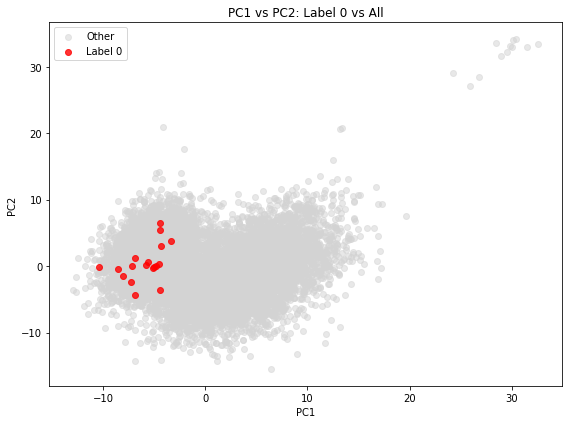

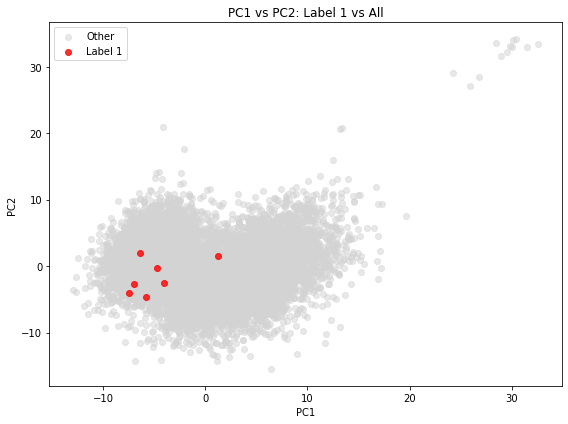

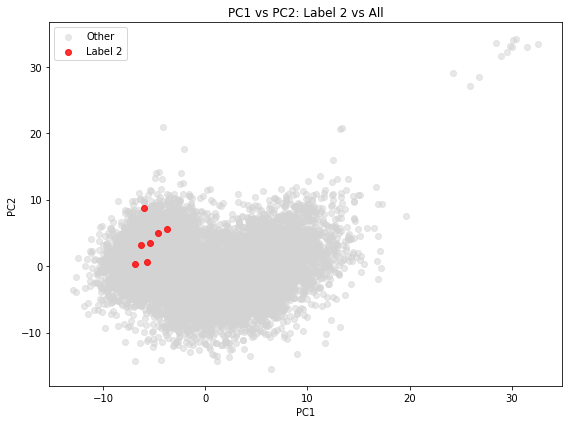

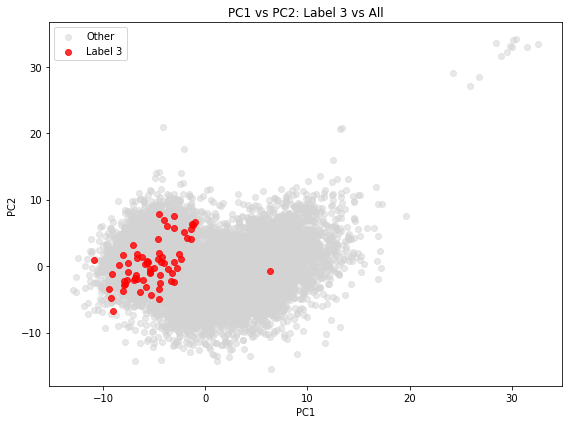

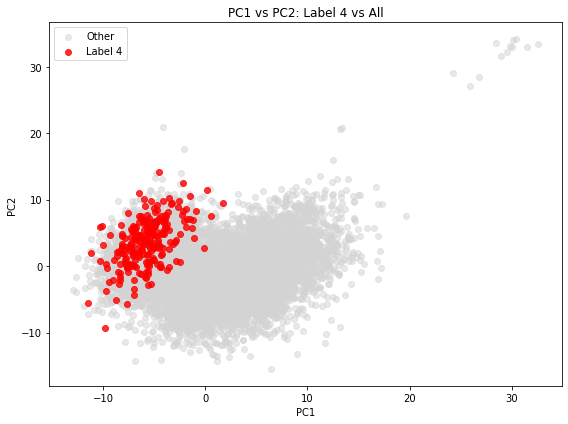

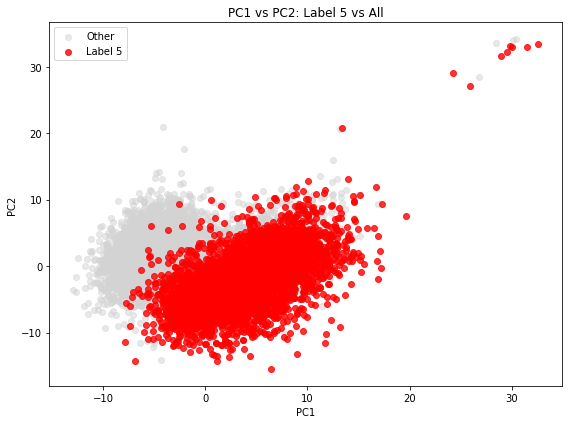

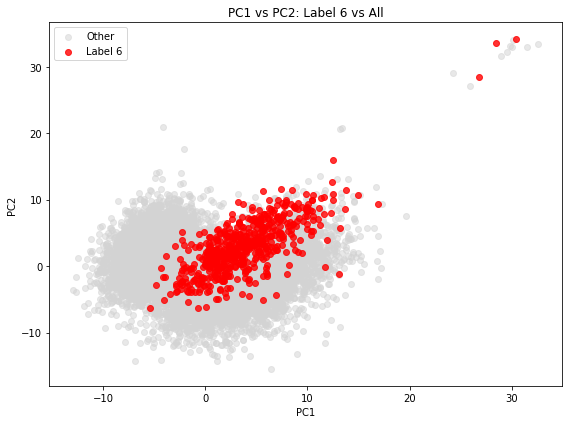

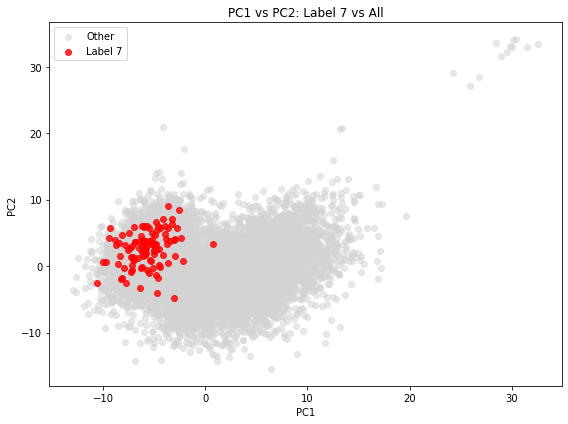

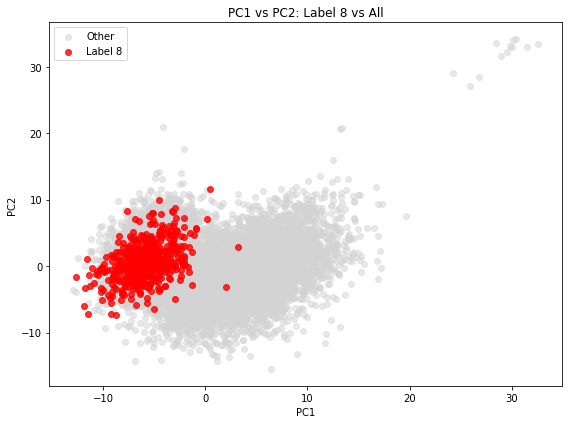

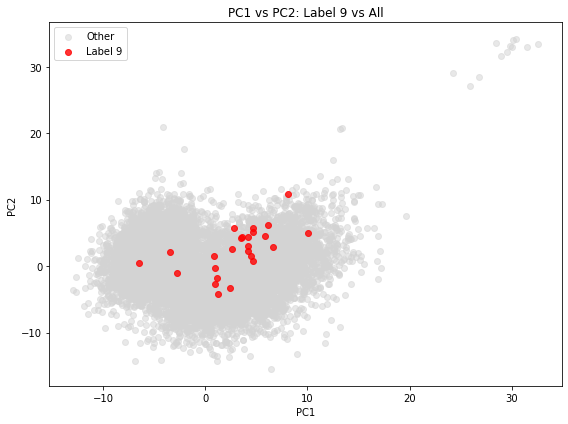

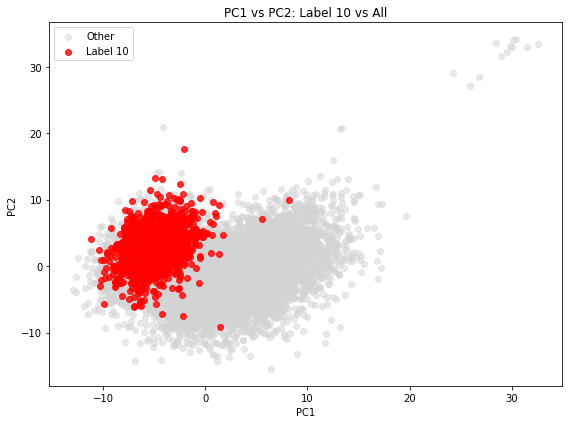

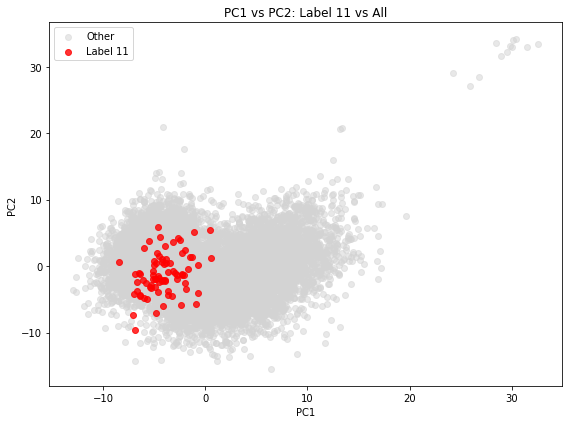

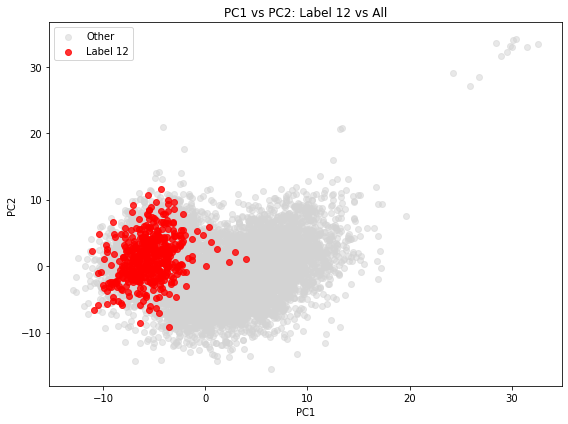

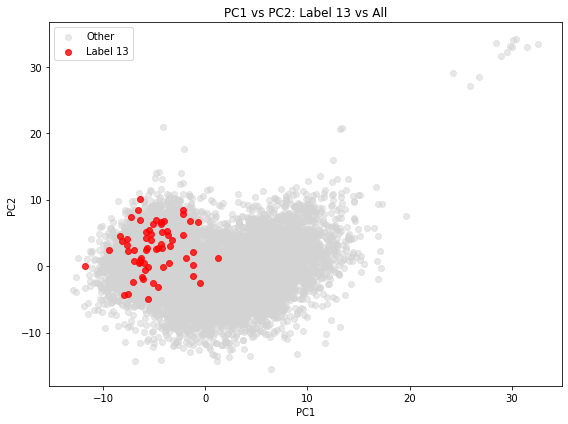

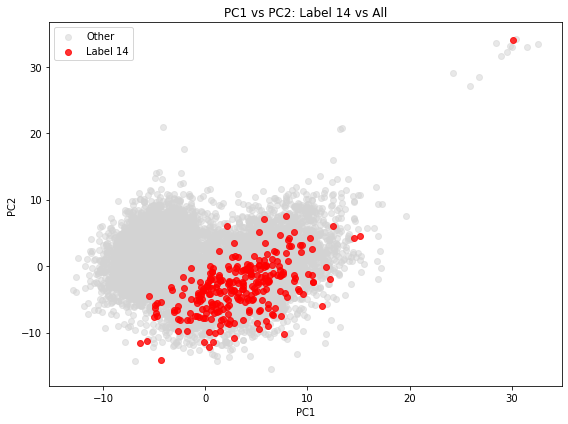

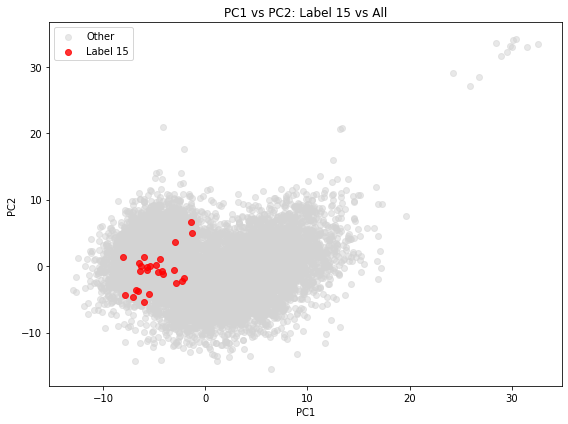

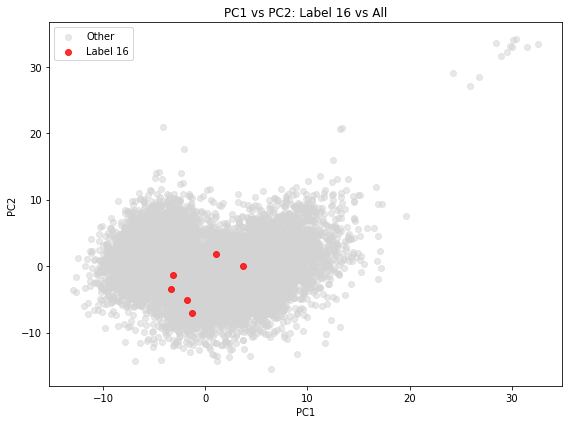

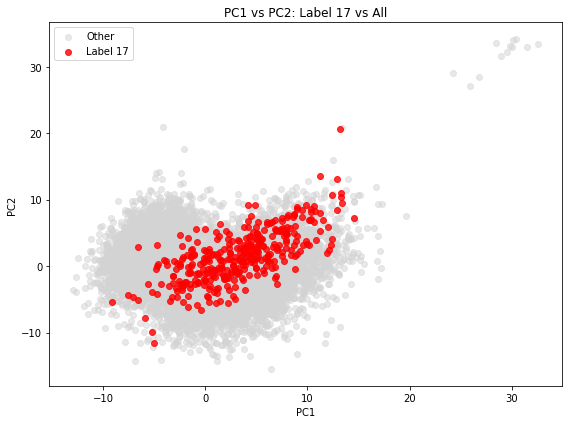

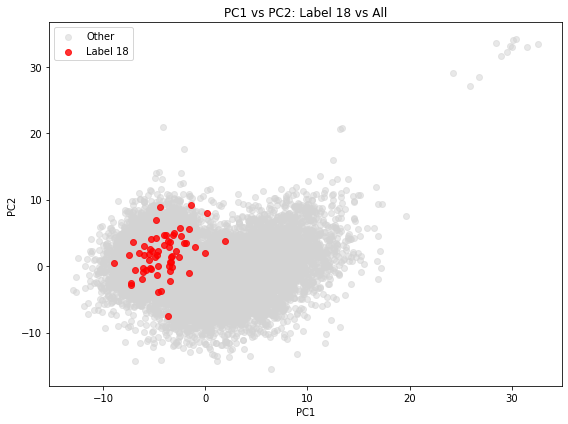

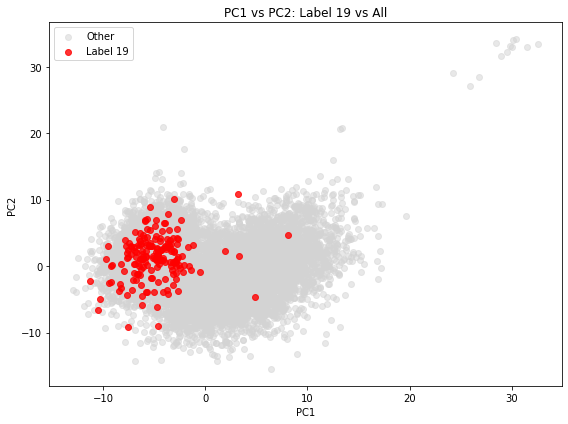

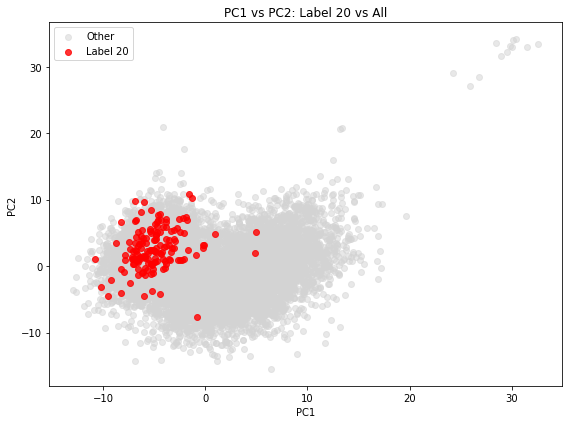

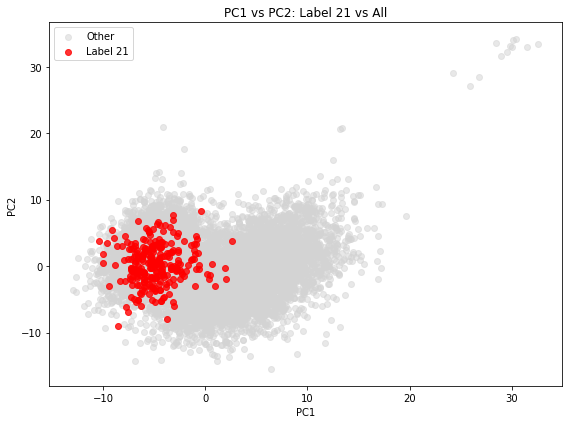

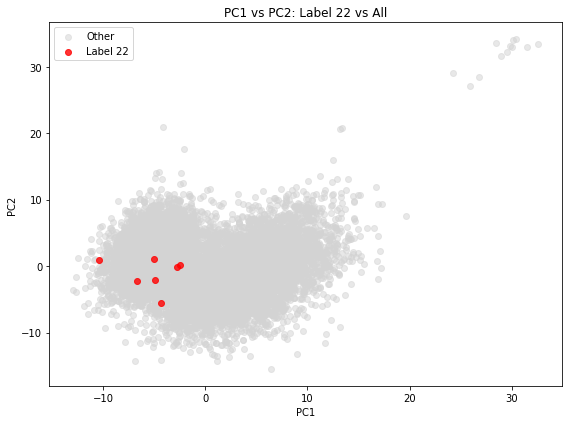

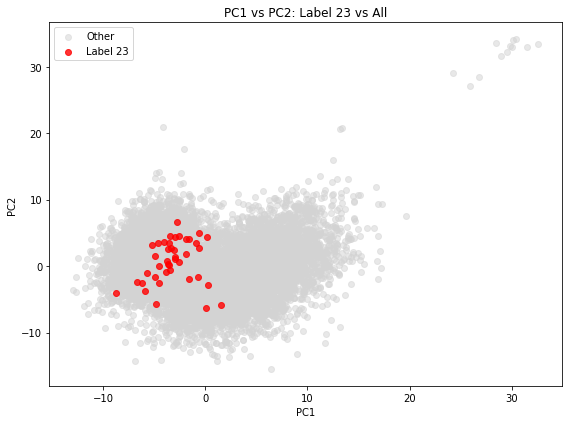

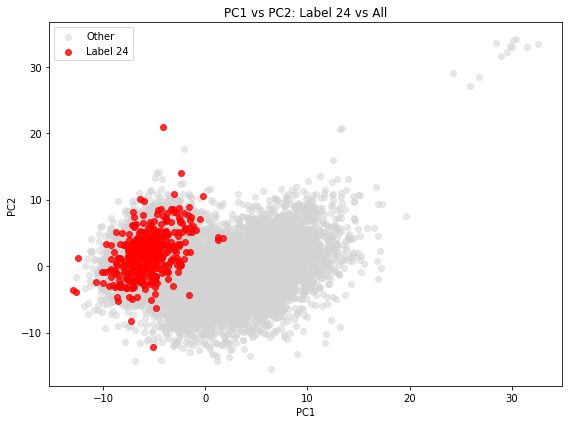

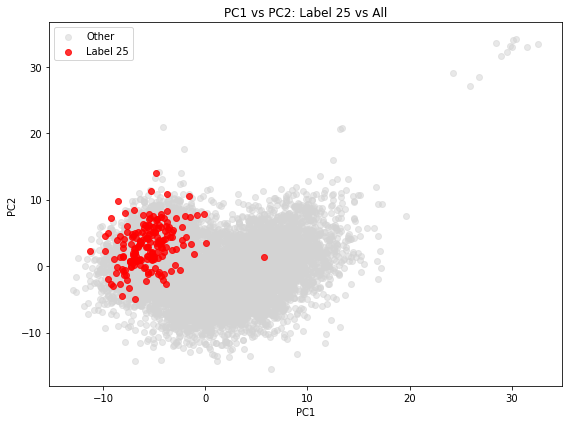

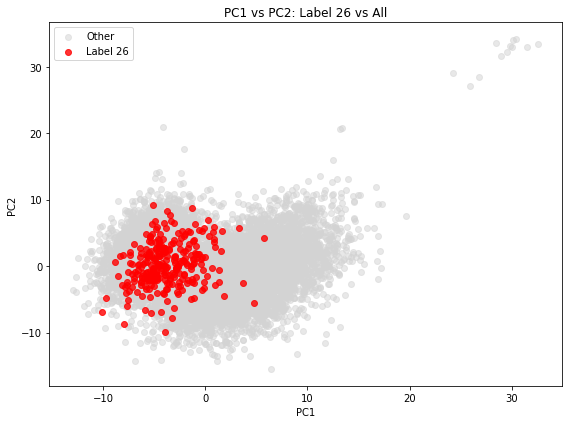

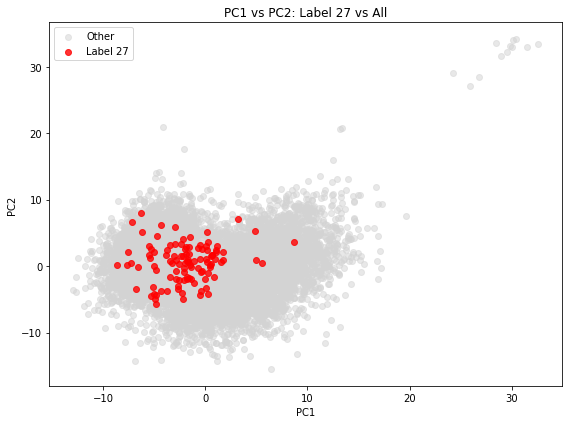

In [89]:
labels = range(28)

plot_label_vs_all(X_pca_labelled, labels)

There are a few outliers which we can consider removing (based on pca graph).

They arise from label 5, 6, 14. We can remove this as those classes have sufficient data. Removing outliers is necessary for SMOTE.

In [90]:
query = f'''
SELECT
    PC1,
    PC2,
    label
FROM 
    ({train_joined})
WHERE
    PC1 < 23 AND
    PC2 < 25
'''

X_pca_labelled_no_outliers = pd.read_sql(query, conn)
print(X_pca_labelled_no_outliers.to_string(index=False))

       PC1        PC2  label
 -6.686283   1.352084     10
  8.742716   7.400855      5
  5.601774   4.273253      5
  9.838185   1.696685      5
 -3.928368  -9.039556      5
 -3.784208  -0.613008      4
 12.342951  -8.151194      5
 -6.693965  -3.818338     11
 -3.947431   2.708754     26
  6.027285   2.569637      5
 -6.123717  -0.585518     24
  8.787518   1.536194      5
 -8.688924  -2.233671     12
 -4.640195  -0.945866     15
 -5.806932   2.474121     13
 -1.125645 -10.690142      5
  3.247079  -7.383952      5
  1.155989   3.980845      6
  3.313239  -0.444689      5
  3.118389  -5.854791      5
 -1.635313  -7.894065      5
  2.773980   1.096105      6
 10.305392   5.338904      6
  3.462618   1.931273      5
  6.477109   2.546110      5
 -7.127312   2.562755     24
  4.019317  -2.771609      5
 -2.813831   2.423569      8
  8.494193  -2.665501      5
 11.707856   2.089780      5
 -5.485290   0.934782      8
 -1.566596   4.165284     10
 -3.907341  -3.053534      8
 -3.635251   5

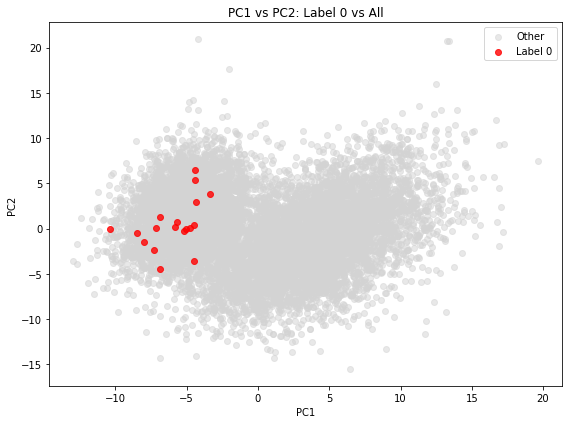

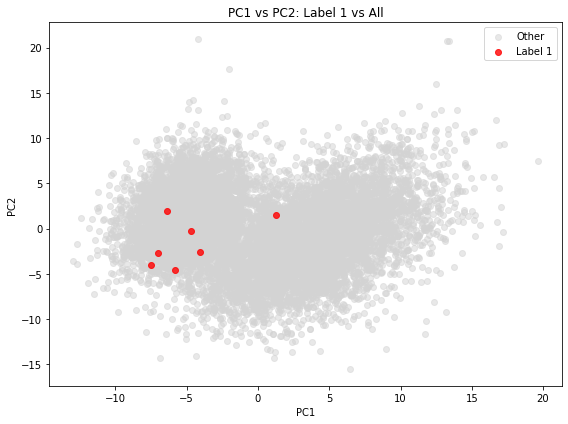

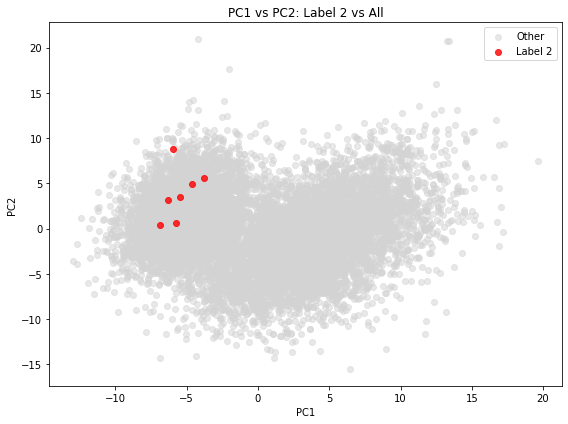

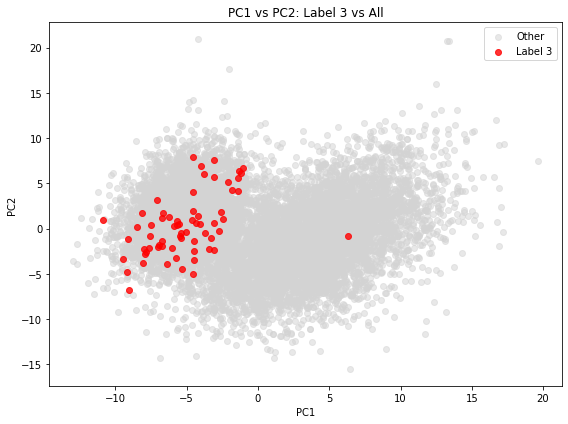

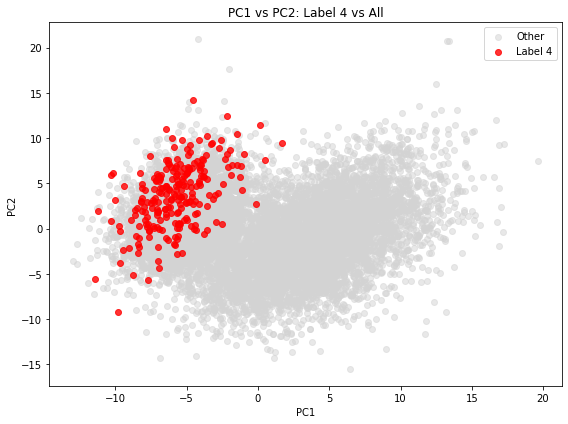

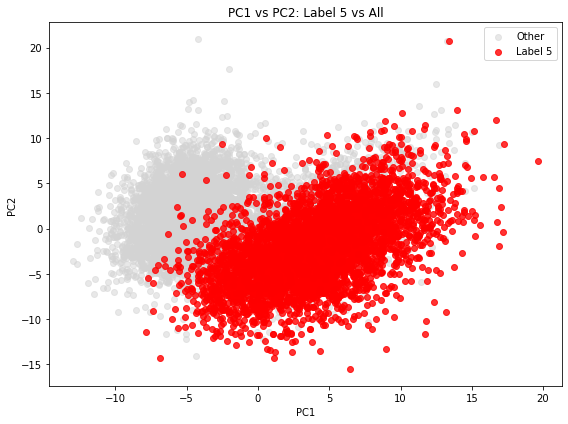

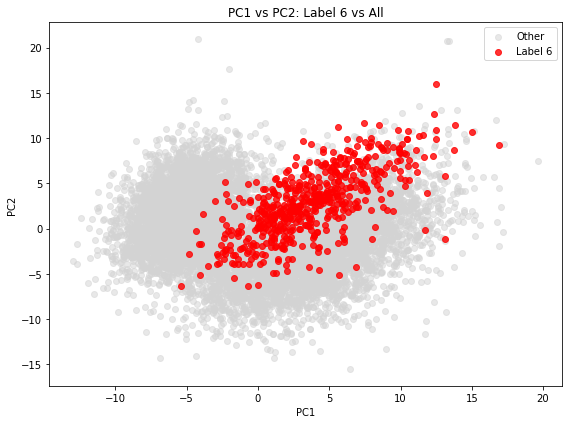

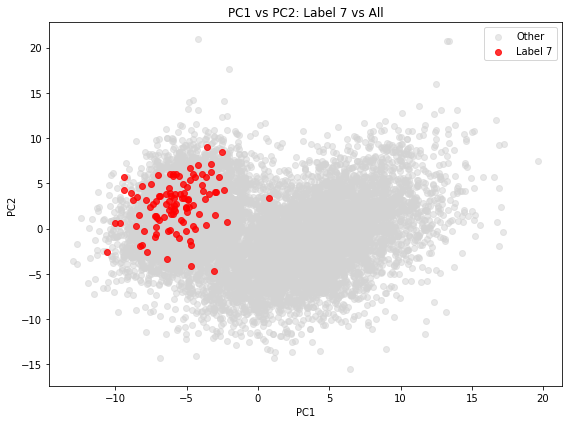

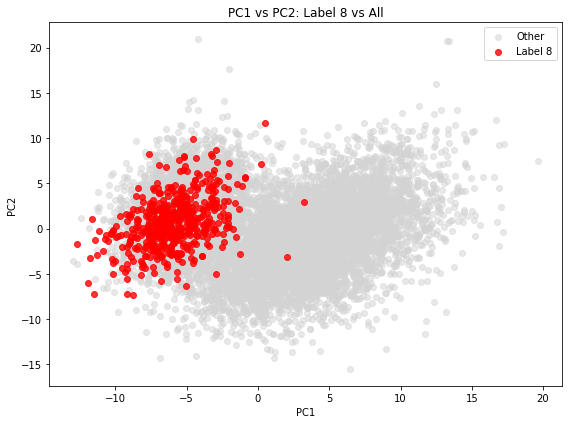

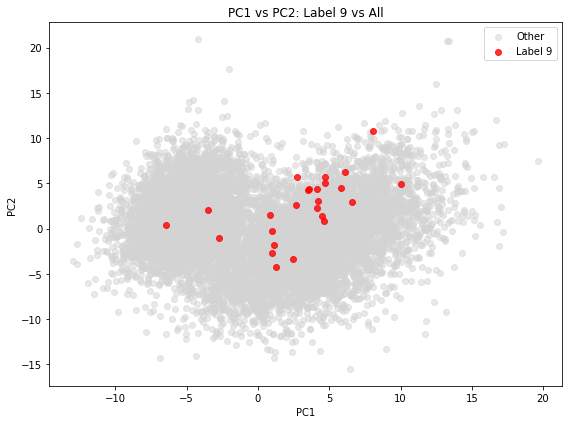

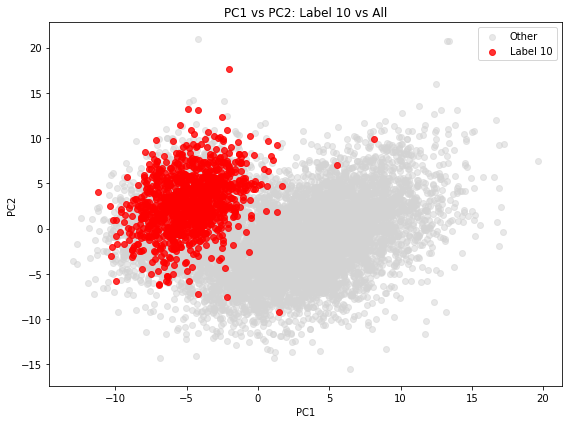

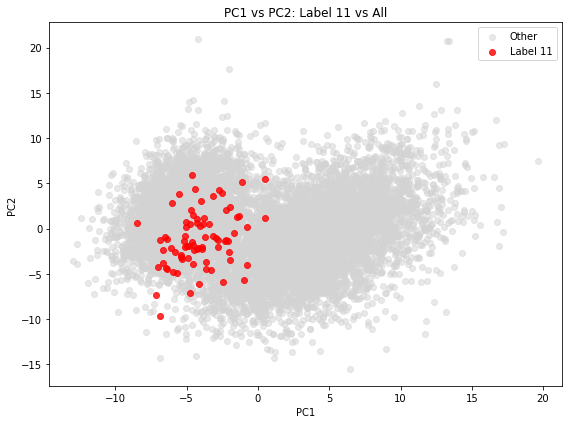

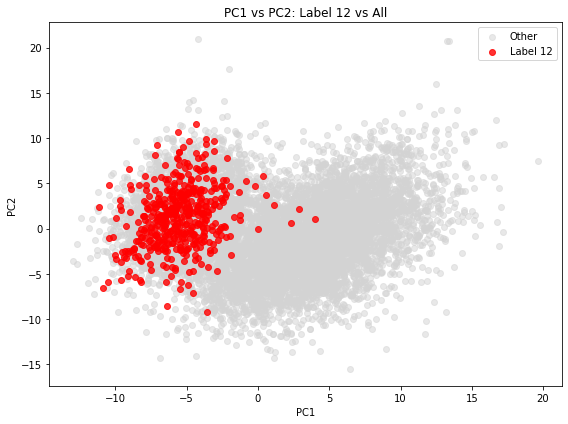

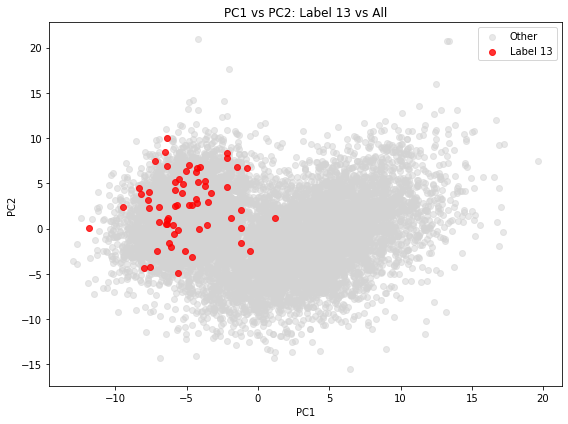

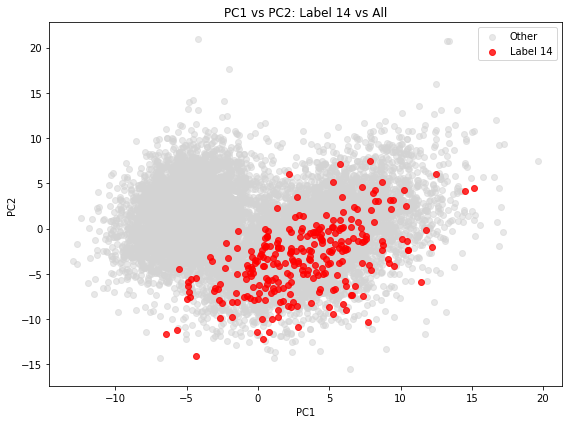

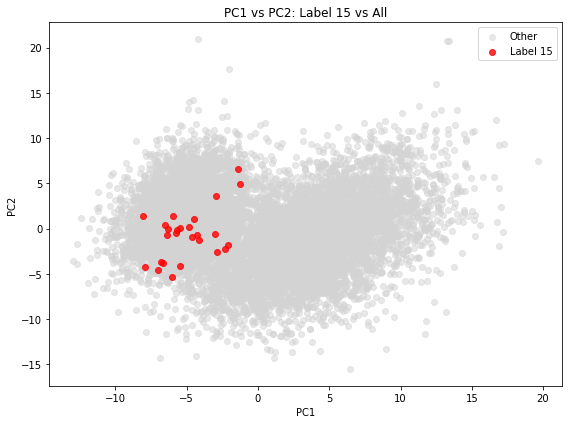

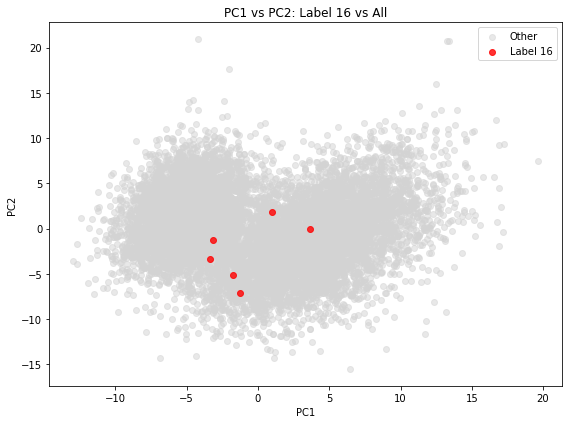

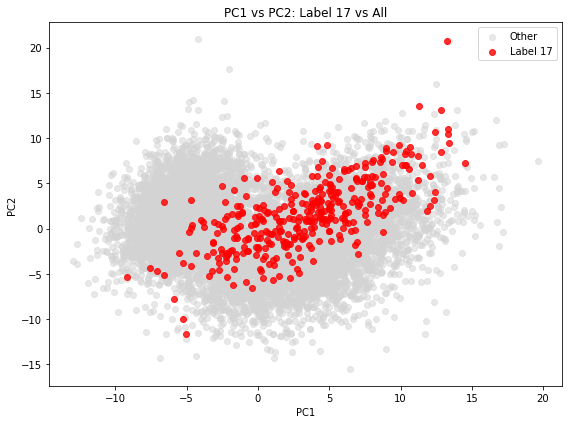

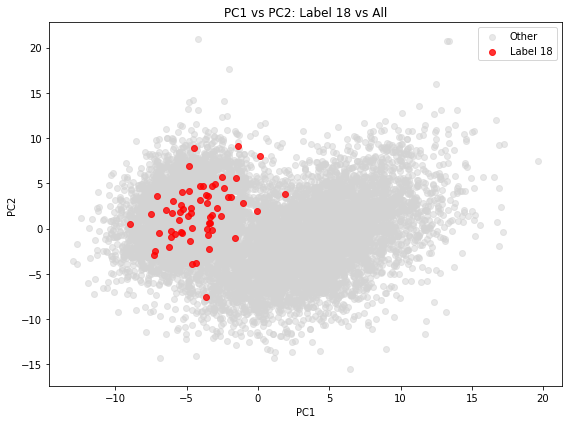

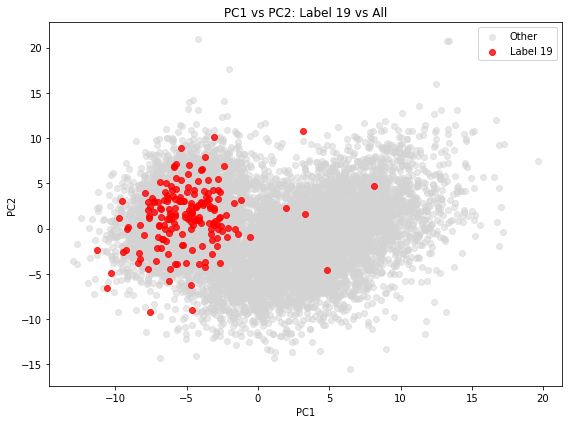

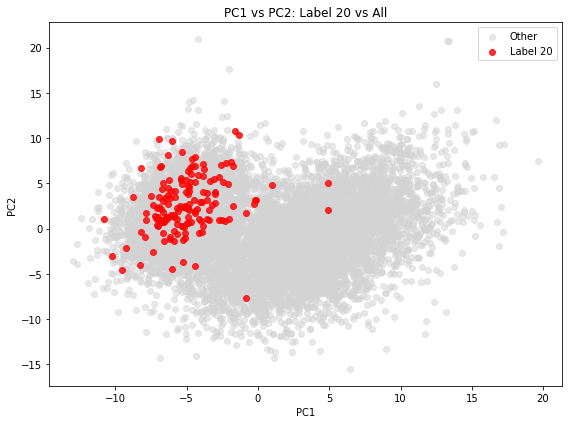

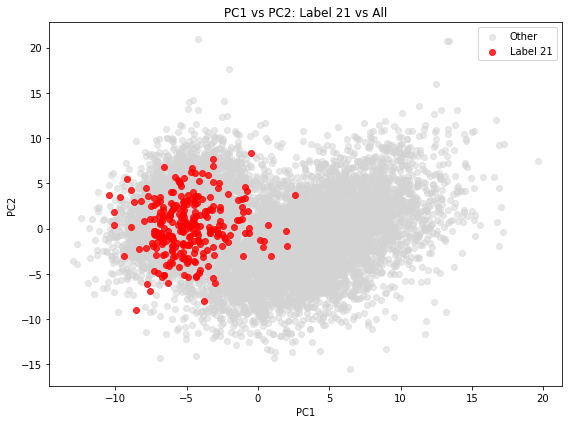

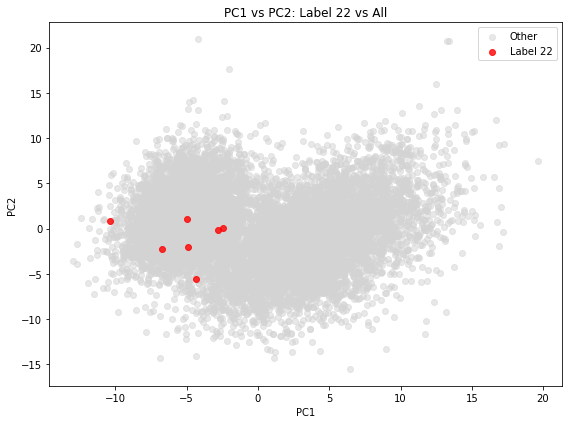

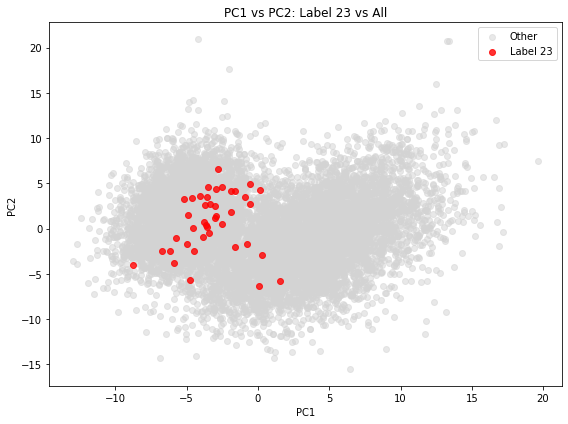

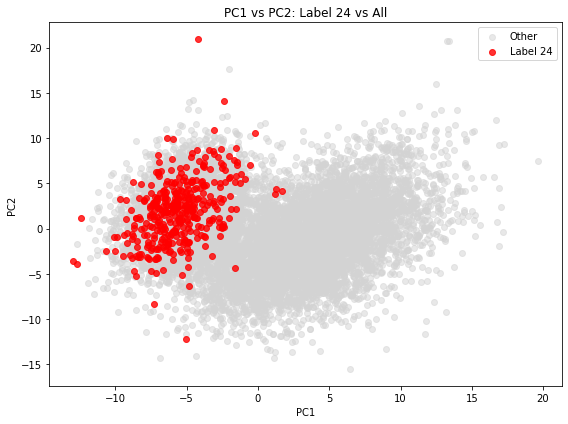

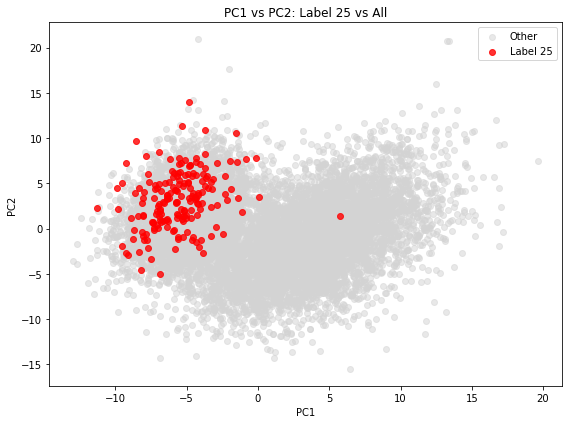

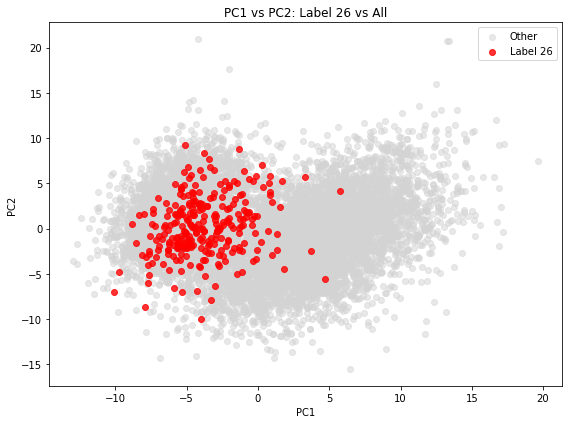

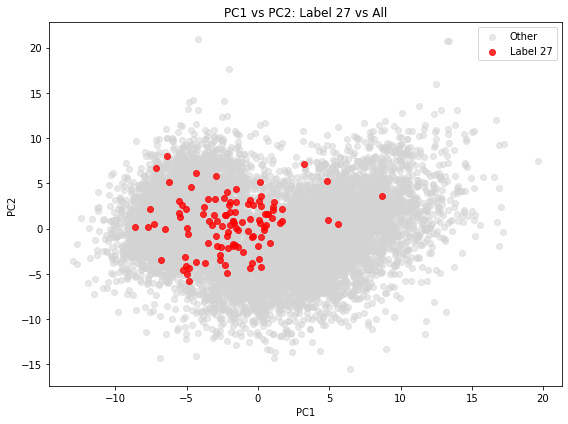

In [91]:
plot_label_vs_all(X_pca_labelled_no_outliers, labels)

SMOTE Sampling strategy

For labels with extreme low counts (less than 10) , use knn 3 as default knn 5 will throw an error since there's not enough data points. In general, we would like to use knn 5 to increase variability hence generalisation, and allows for smoother interpolation.

For now, set to 50 data points.

smote_low = SMOTE(
    sampling_strategy={1: 50, 2: 50, 22: 50, 16:50},  
    k_neighbors=3,
    random_state=42
)

In [94]:
low_count_labels = [1,2,16,22]

# Split features and labels
X = X_pca_labelled_no_outliers.drop("label", axis=1)
y = X_pca_labelled_no_outliers["label"]

smote_low = SMOTE(
    sampling_strategy={1: 50, 2: 50, 16: 50, 22:50},  
    k_neighbors=3,
    random_state=42
)

X_smote_low, y_smote_low = smote_low.fit_resample(X,y)

X_smote_low = pd.DataFrame(X_smote_low, columns=['PC1', 'PC2'])
y_smote_low = pd.DataFrame(y_smote_low, columns=['label'])

smote_low = pd.concat([X_smote_low, y_smote_low], axis=1)

X_smote_low.to_sql("X_smote_low", conn, index=False, if_exists="replace")
y_smote_low.to_sql("y_smote_low", conn, index=False, if_exists="replace")
smote_low.to_sql("smote_low", conn, index=False, if_exists="replace")

10161

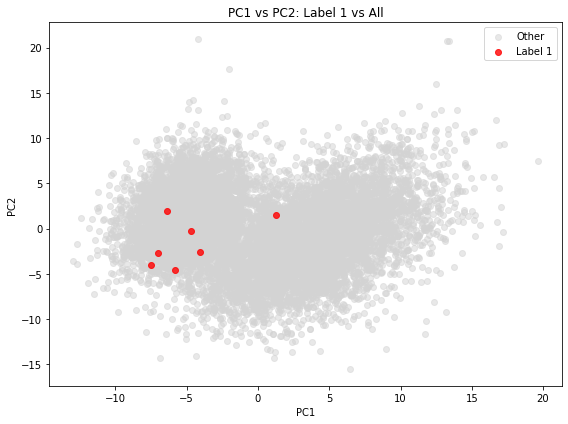

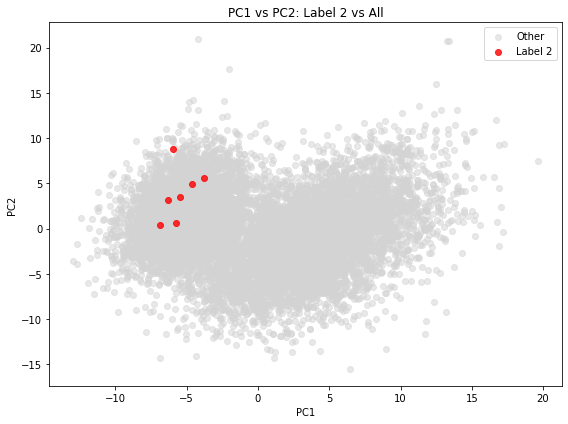

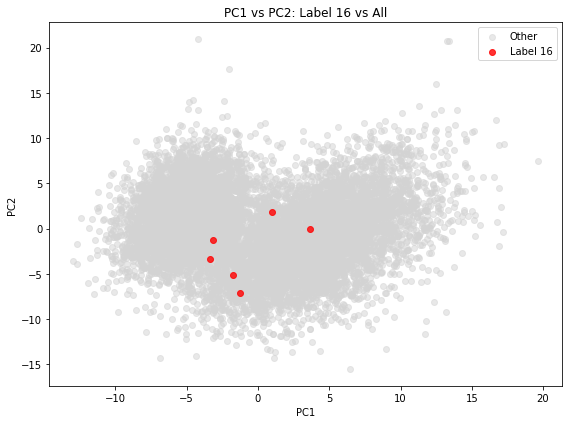

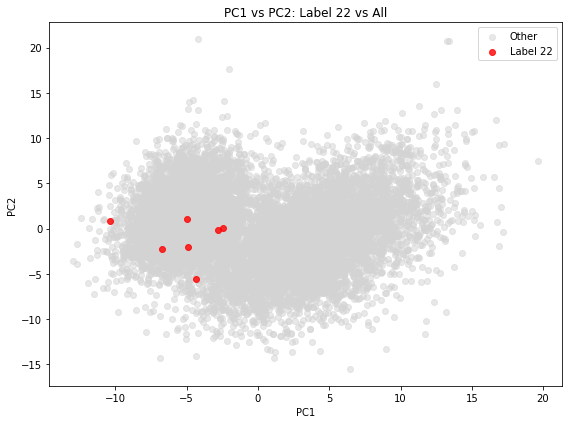

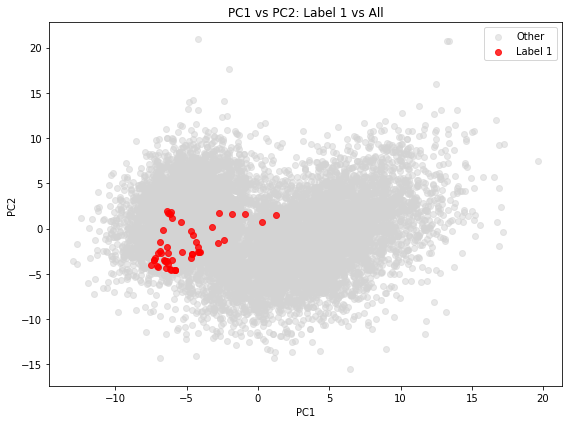

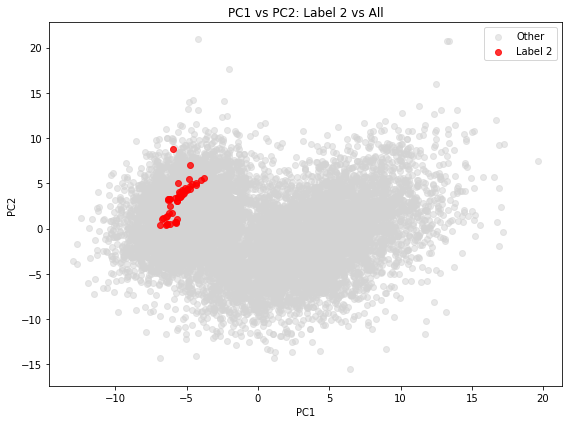

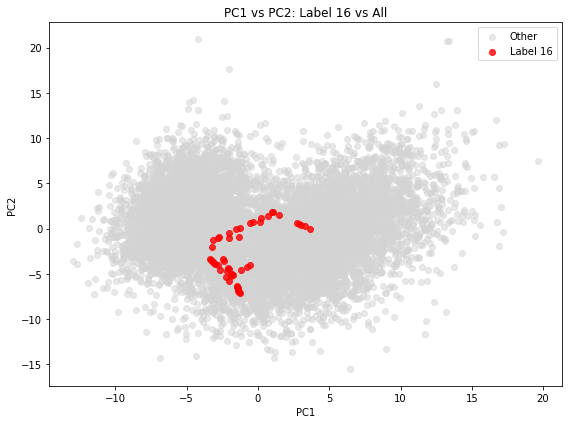

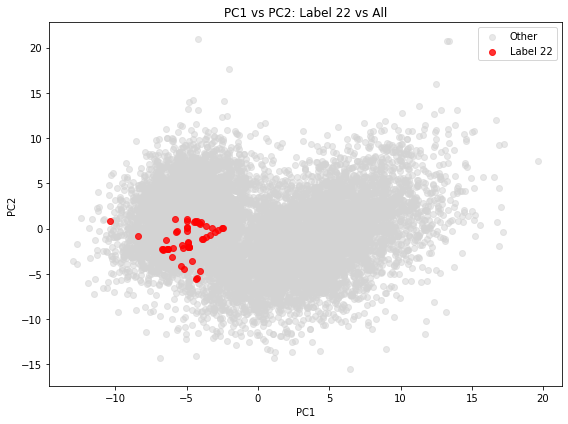

In [96]:
# Visualise smote
plot_label_vs_all(X_pca_labelled_no_outliers, low_count_labels)
plot_label_vs_all(smote_low, low_count_labels)

In [119]:
smote = SMOTE(
    sampling_strategy={
        12: 500,   # 457 -> resample to 500
        24: 500,   # 385 -> resample to 500
        17: 500,   # 354 -> resample to 500
        26: 500,   # 278 -> resample to 500
        21: 500,   # 269 -> resample to 500
        14: 500,   # 264 -> resample to 500
        4: 500,    # 238 -> resample to 500
        25: 500,   # 184 -> resample to 500
        19: 500,   # 177 -> resample to 500
        20: 500,   # 153 -> resample to 500
        27: 200,   # 107 -> resample to 200
        7: 200,    # 103 -> resample to 200
        11: 200,   # 78 -> resample to 200
        3: 200,    # 65 -> resample to 200
        13: 200,   # 62 -> resample to 200
        18: 200,   # 60 -> resample to 200
        23: 200,   # 41 -> resample to 200
        15: 200,   # 26 -> resample to 200
        9: 200,    # 25 -> resample to 200
        0: 200     # 18 -> resample to 200
    },  
    k_neighbors=5,
    random_state=42
)

X_smote, y_smote = smote.fit_resample(X_smote_low,y_smote_low)

X_smote = pd.DataFrame(X_smote, columns=['PC1', 'PC2'])
y_smote = pd.DataFrame(y_smote, columns=['label'])

smote = pd.concat([X_smote, y_smote], axis=1)

X_smote.to_sql("X_smote", conn, index=False, if_exists="replace")
y_smote.to_sql("y_smote", conn, index=False, if_exists="replace")
smote.to_sql("smote", conn, index=False, if_exists="replace")

13818

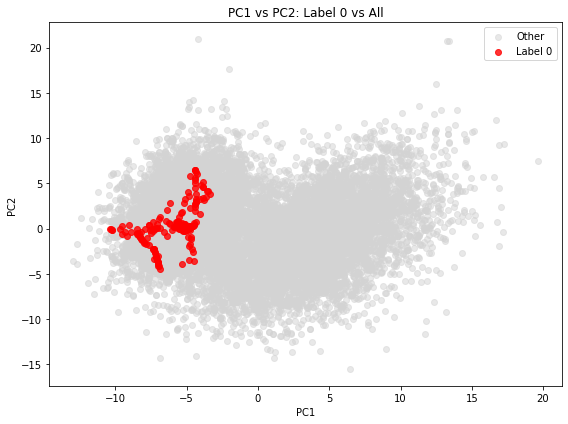

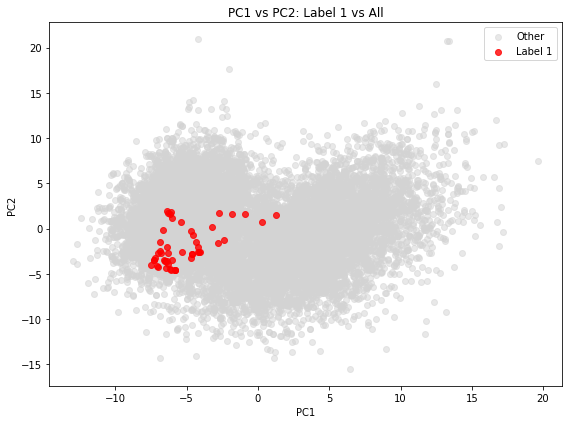

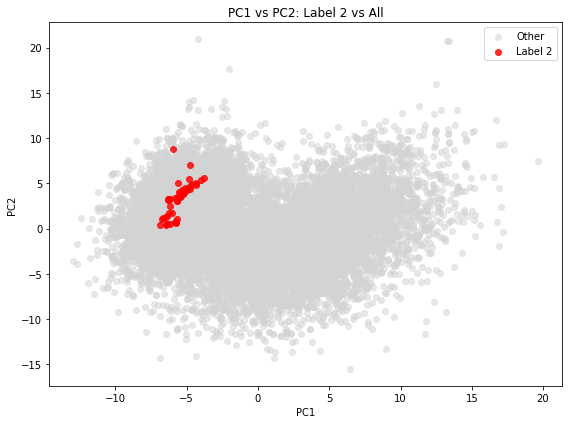

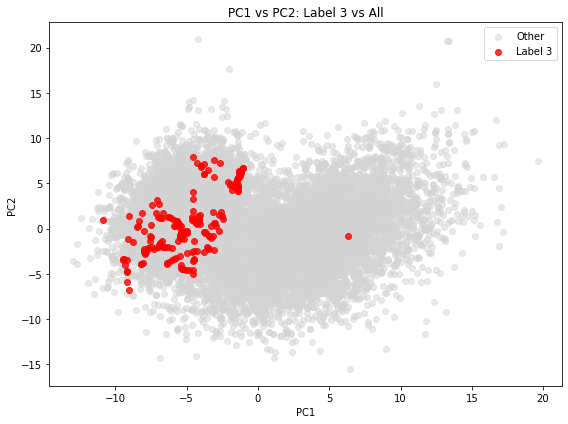

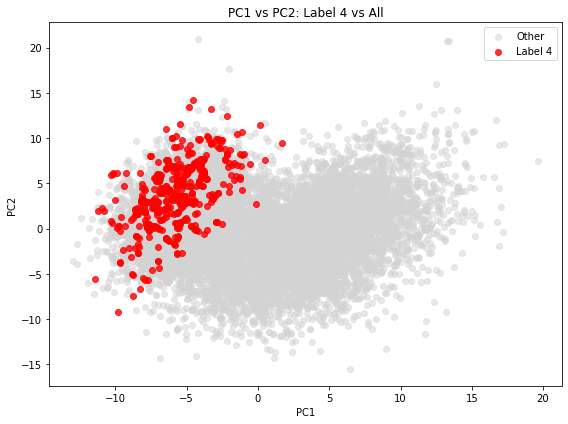

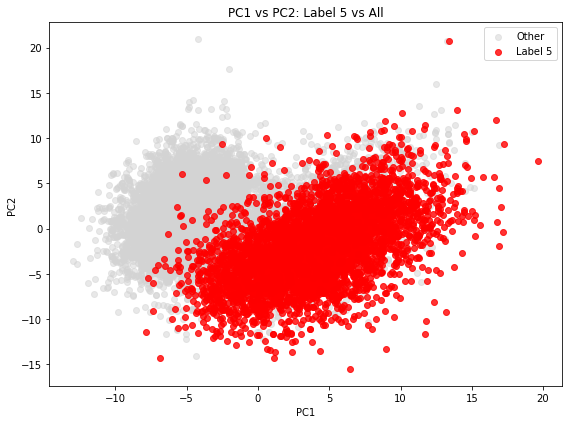

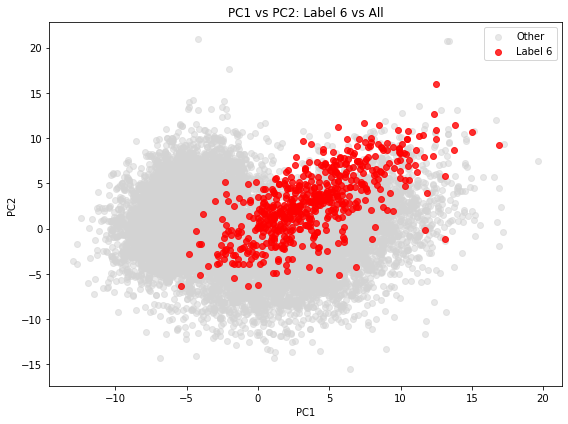

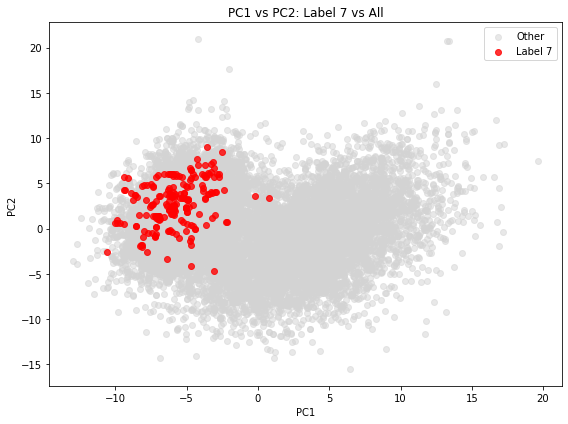

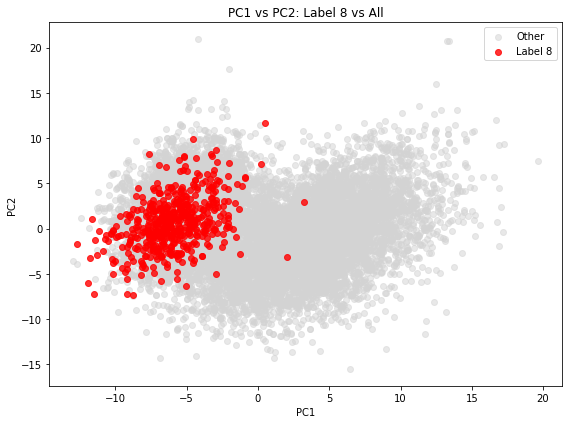

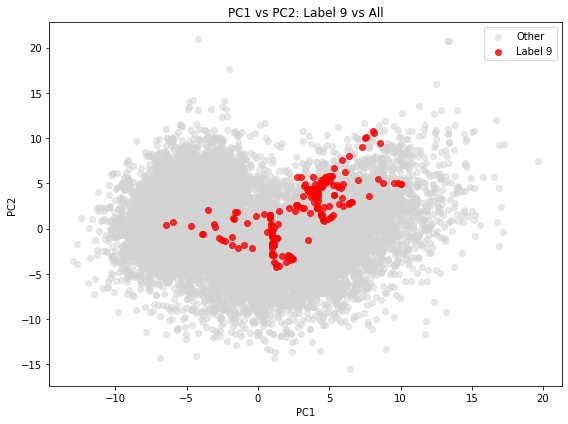

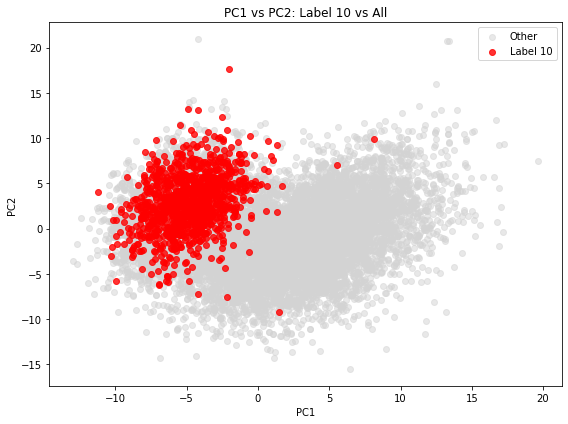

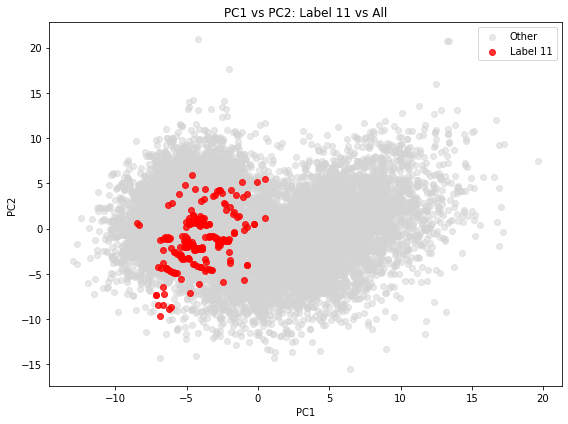

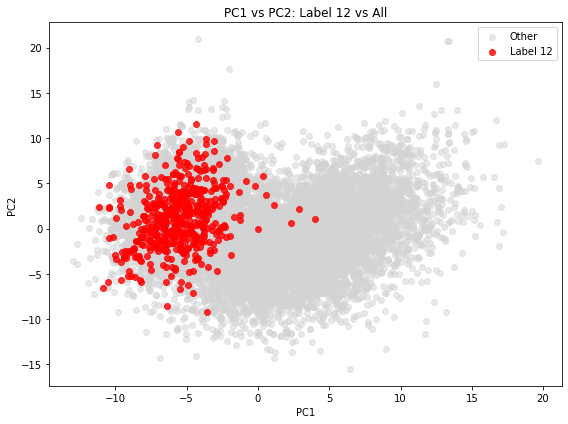

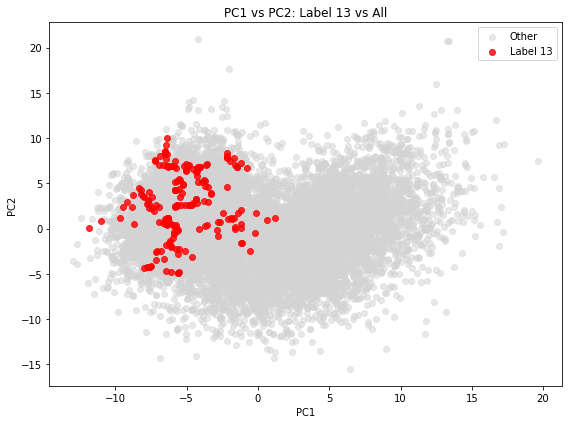

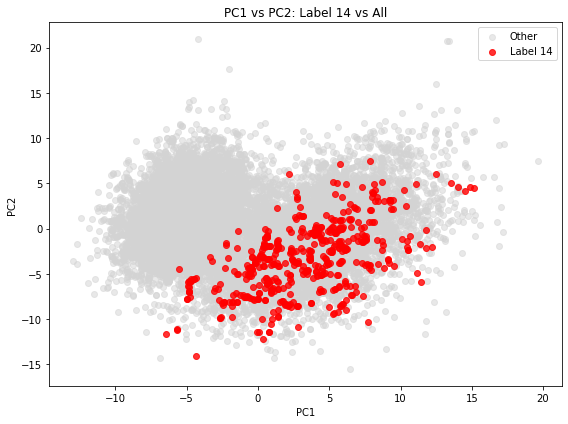

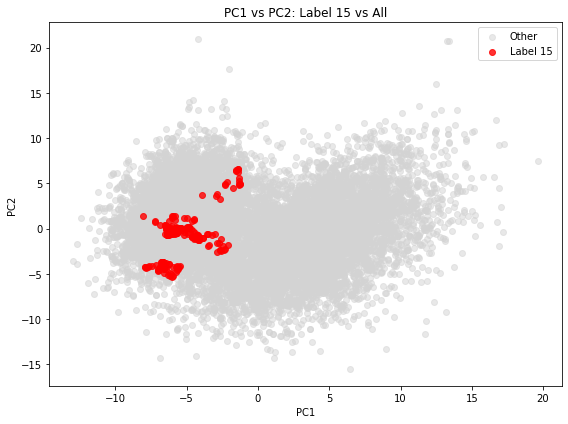

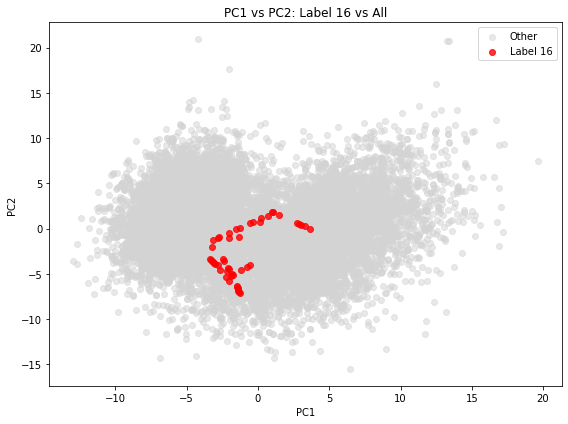

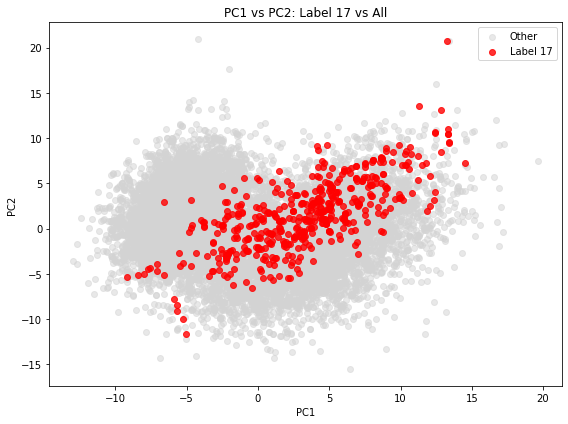

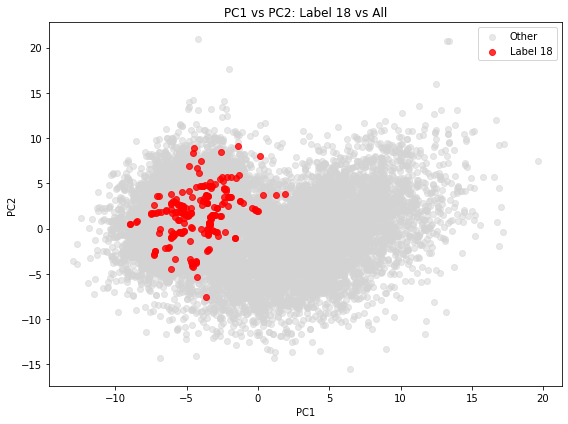

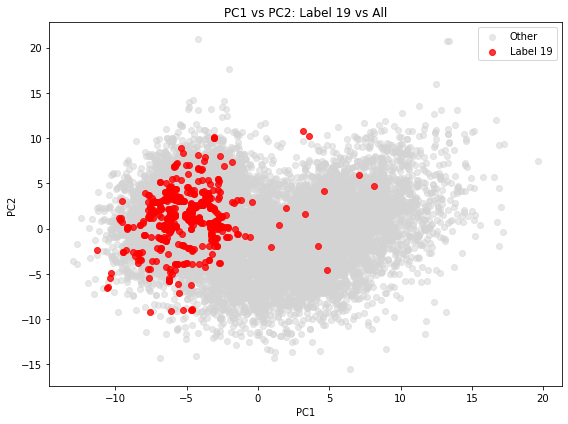

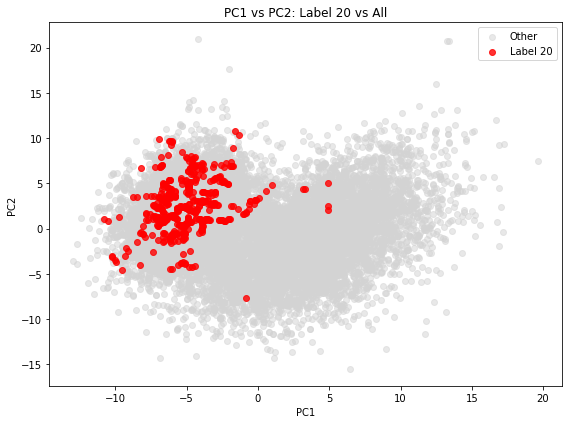

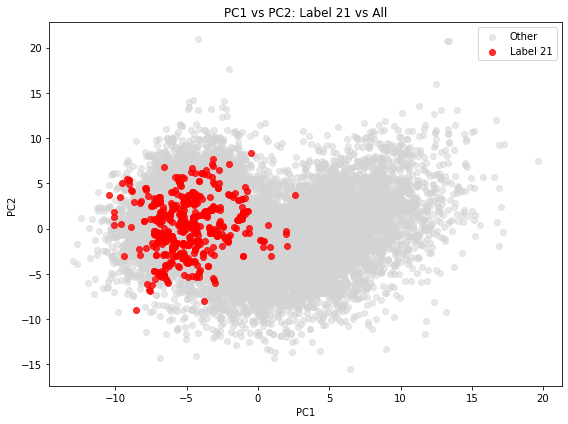

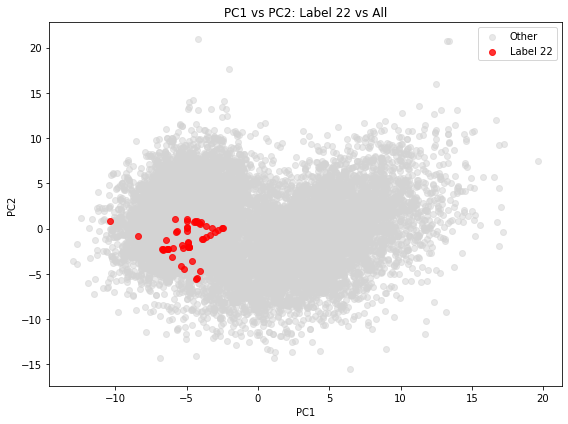

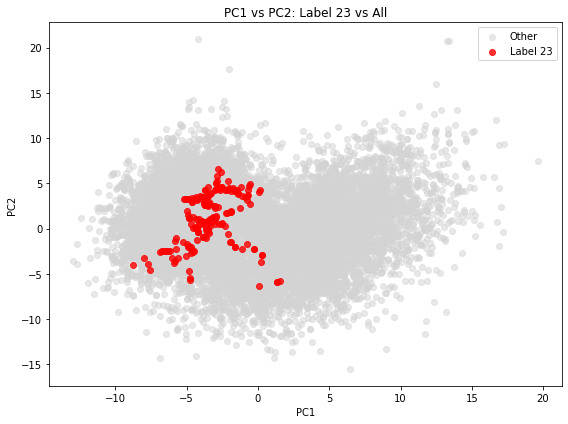

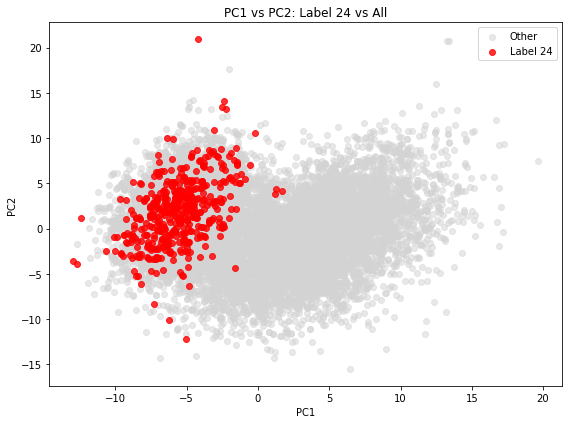

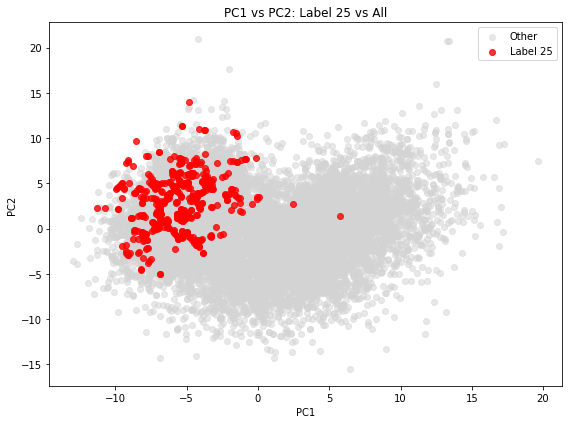

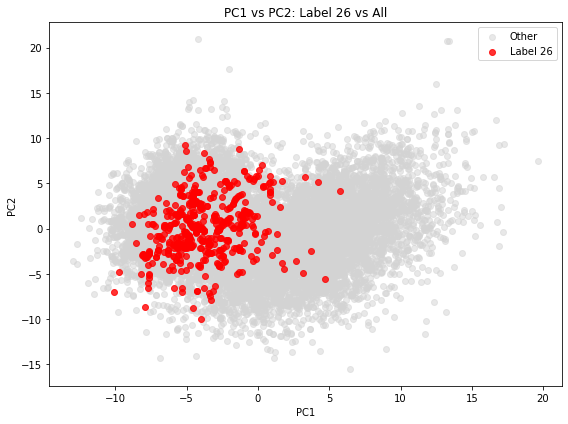

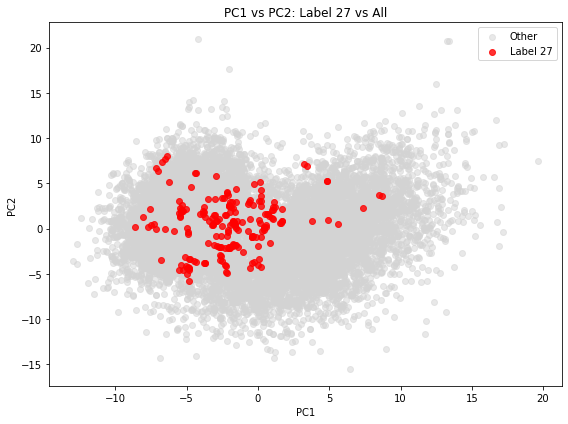

In [120]:
# Visualise smote
plot_label_vs_all(smote,labels)

In [121]:
# Examine smote label distribution in training data
query = '''
SELECT label, COUNT(*) AS count 
FROM smote 
GROUP BY label
ORDER BY count DESC'''

smote_label_distribution = pd.read_sql(query, conn)
print(smote_label_distribution.to_string(index=False))

 label  count
     5   4471
    10   1081
     6    550
     8    516
    26    500
    25    500
    24    500
    21    500
    20    500
    19    500
    17    500
    14    500
    12    500
     4    500
    27    200
    23    200
    18    200
    15    200
    13    200
    11    200
     9    200
     7    200
     3    200
     0    200
    22     50
    16     50
     2     50
     1     50


In [130]:
# Apply Tomek Links
tomek = TomekLinks(sampling_strategy='all') 
X_tomek, y_tomek = tomek.fit_resample(X_smote, y_smote)

X_tomek = pd.DataFrame(X_tomek, columns=['PC1', 'PC2'])
y_tomek = pd.DataFrame(y_tomek, columns=['label'])

tomek = pd.concat([X_tomek, y_tomek], axis=1)

X_tomek.to_sql("X_tomek", conn, index=False, if_exists="replace")
y_tomek.to_sql("y_tomek", conn, index=False, if_exists="replace")
tomek.to_sql("tomek", conn, index=False, if_exists="replace")

9306

In [134]:
# Examine smote label distribution in training data
query = '''
SELECT label, COUNT(*) AS count 
FROM tomek 
GROUP BY label
ORDER BY count DESC'''

tomek_label_distribution = pd.read_sql(query, conn)
print(tomek_label_distribution.to_string(index=False))

 label  count
     5   3846
    10    571
     4    339
    25    338
    19    329
    21    316
    20    315
    26    314
    14    310
    17    279
     6    274
    24    272
    12    247
     8    245
     0    140
     9    139
    15    138
    18    122
    27    115
    11    114
     3    113
    13    110
    23    109
     7    102
    22     29
    16     28
     2     26
     1     26


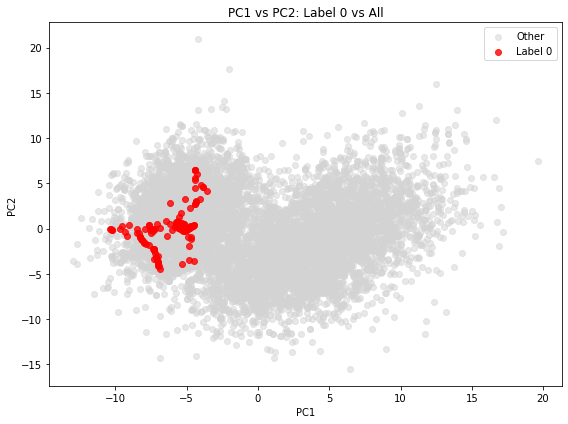

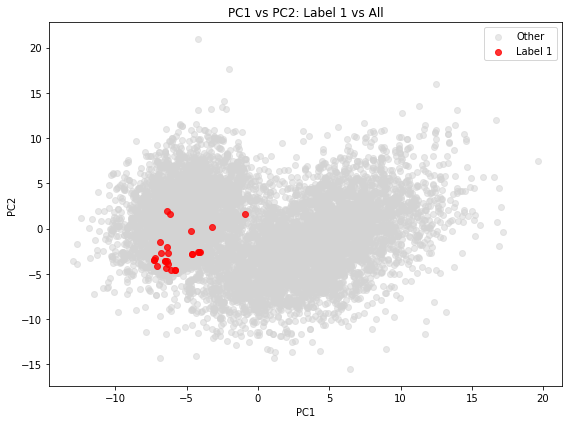

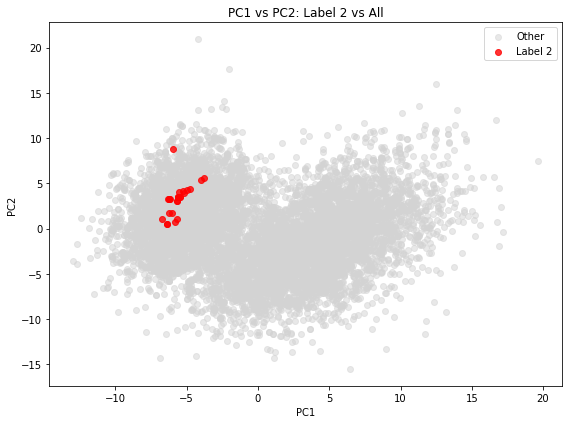

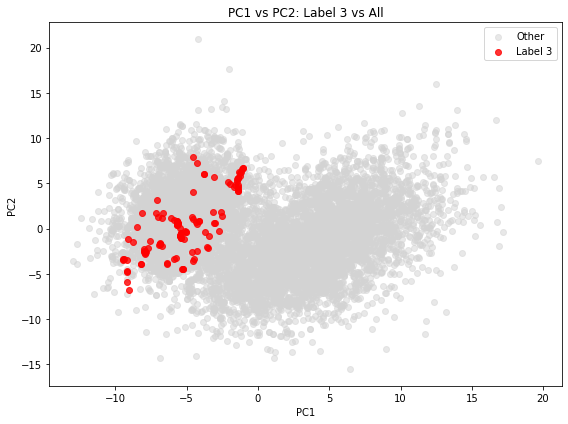

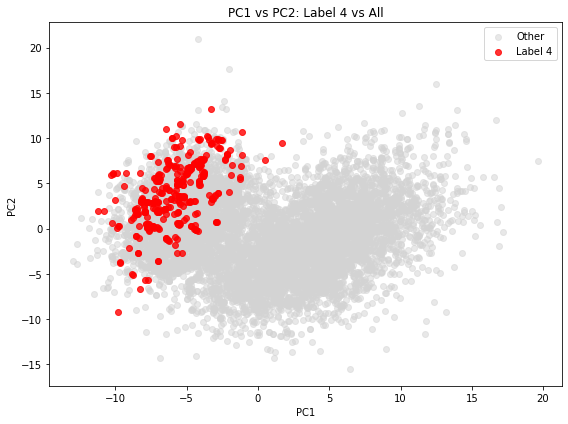

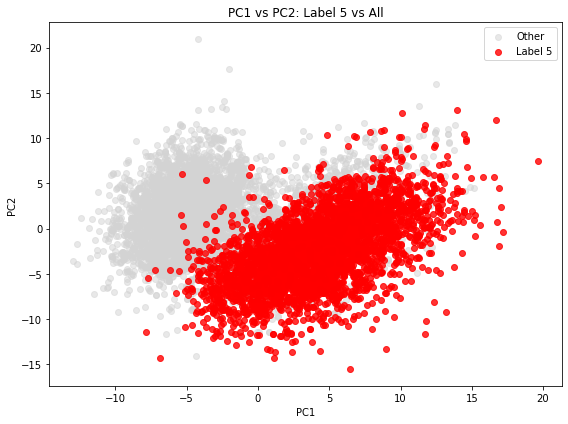

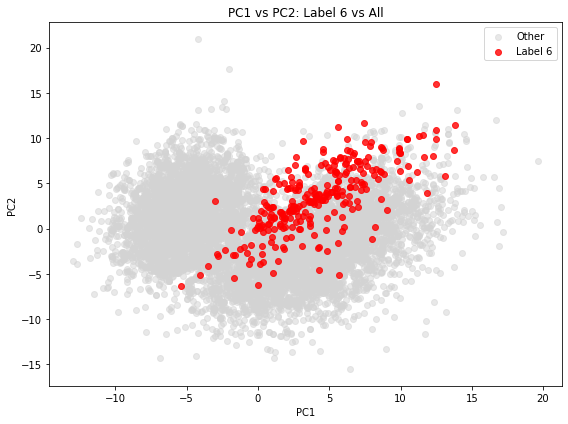

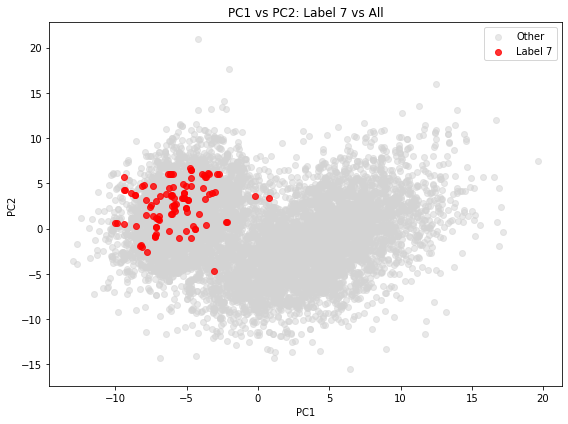

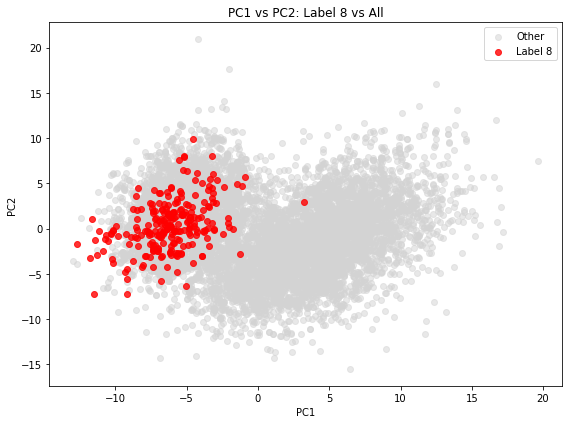

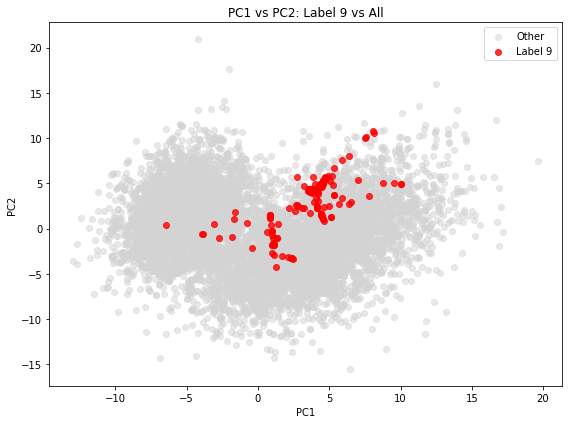

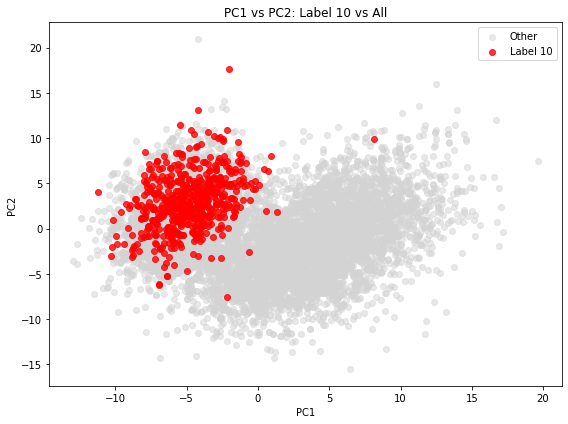

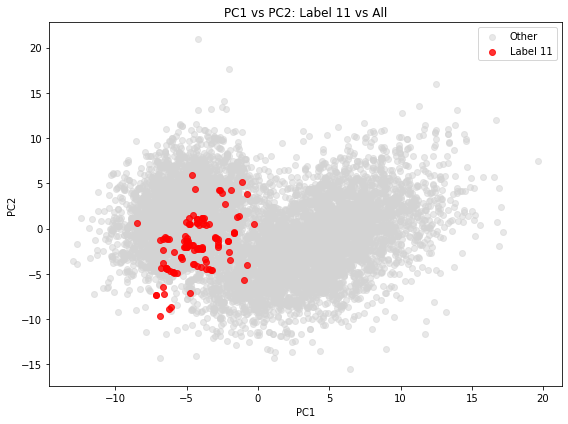

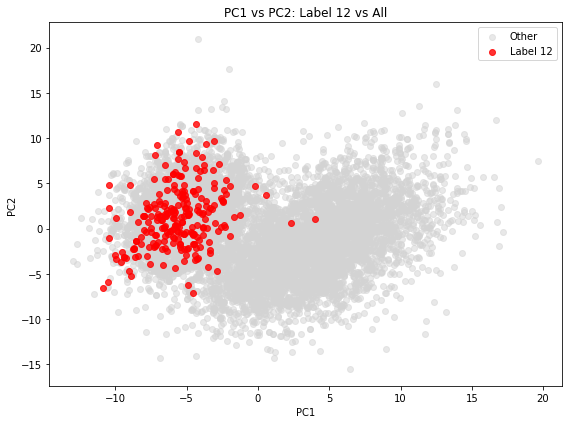

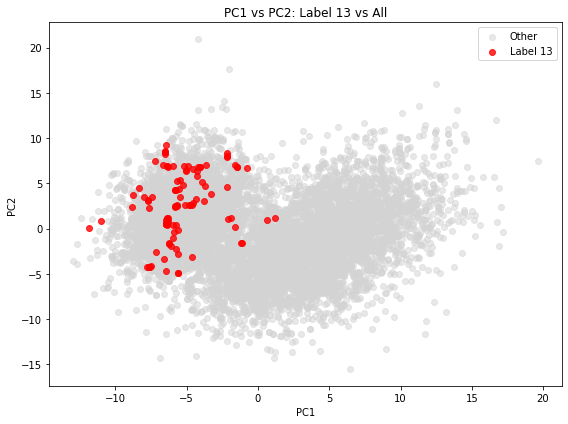

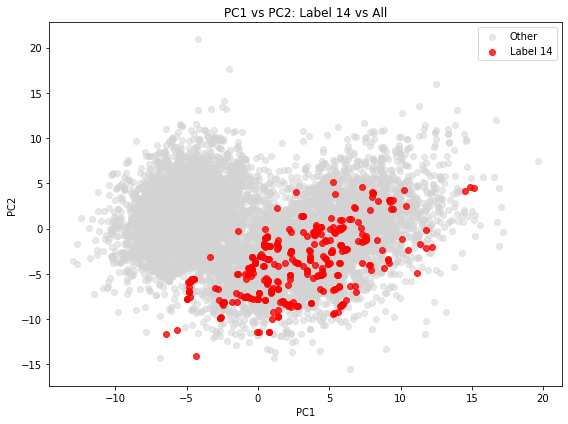

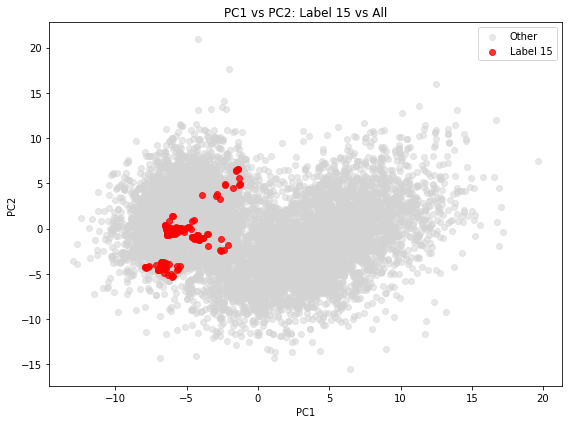

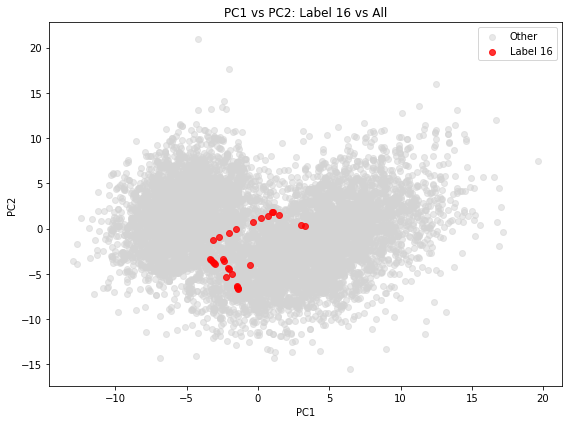

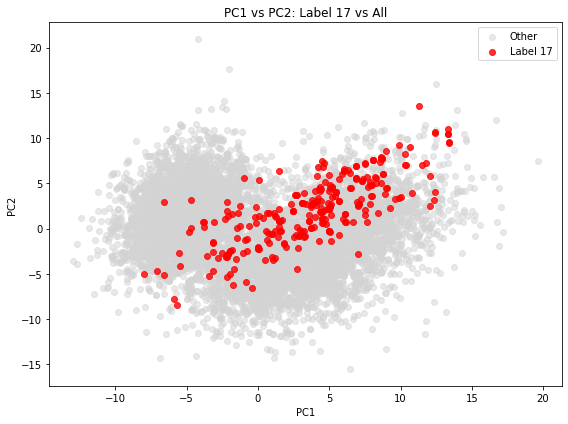

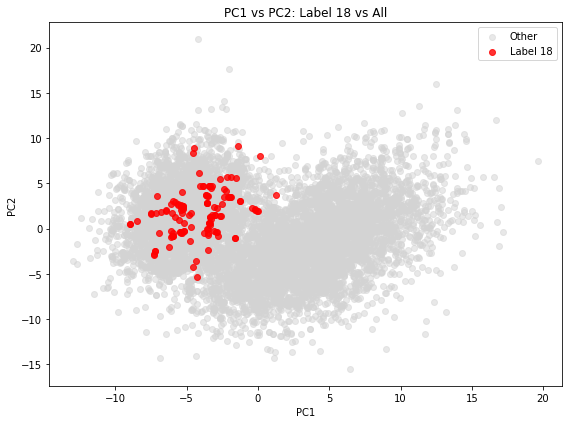

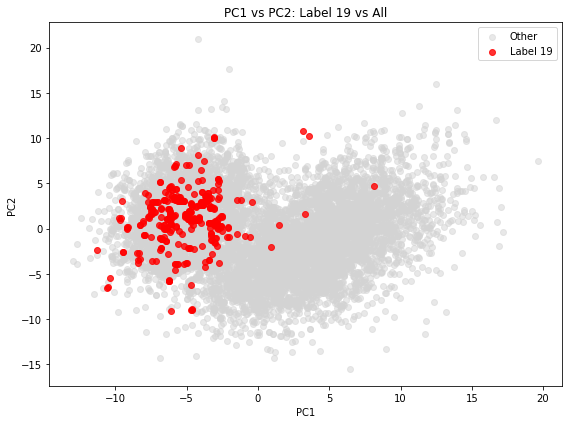

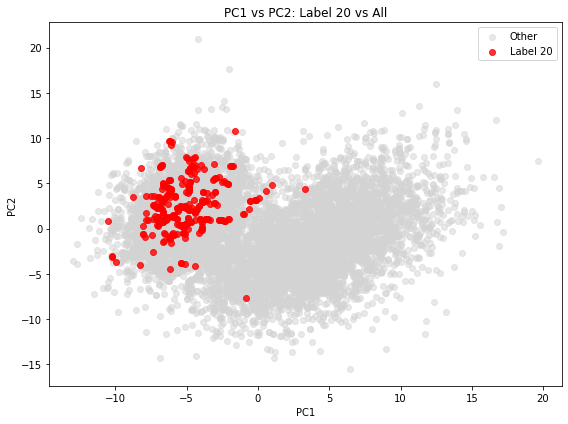

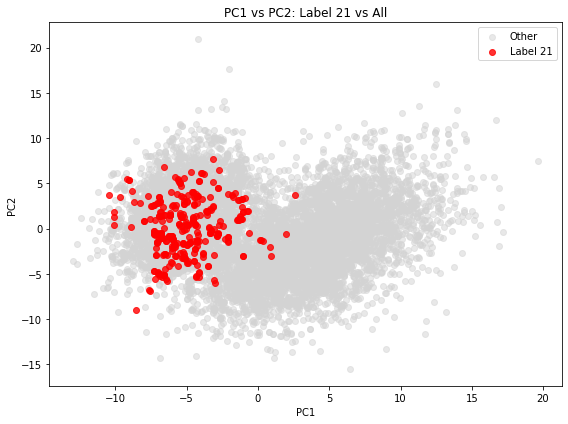

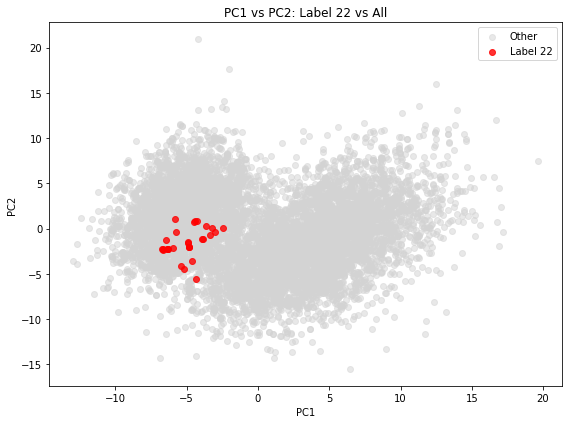

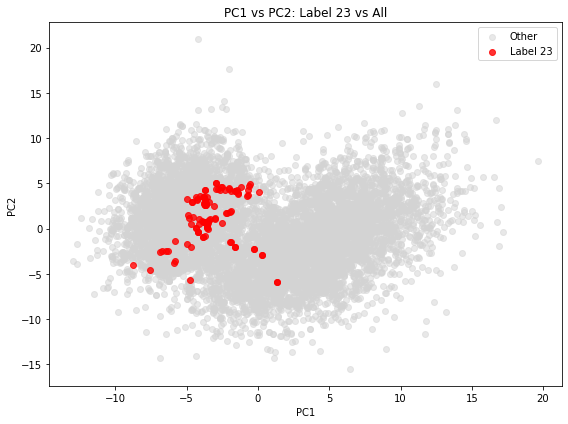

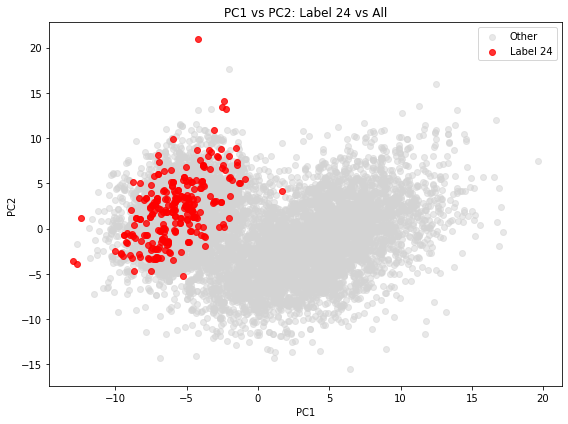

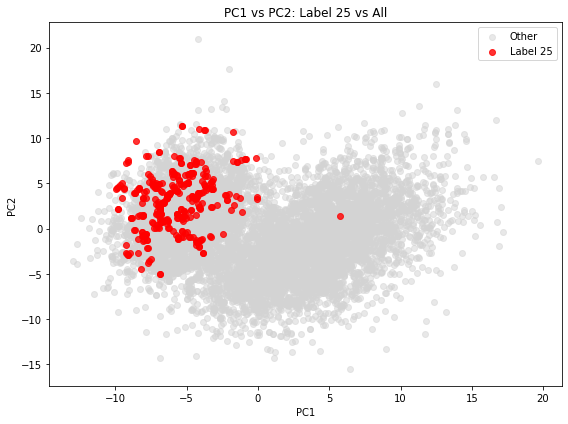

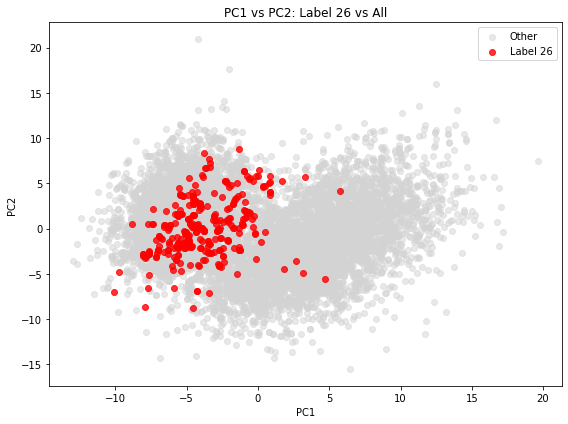

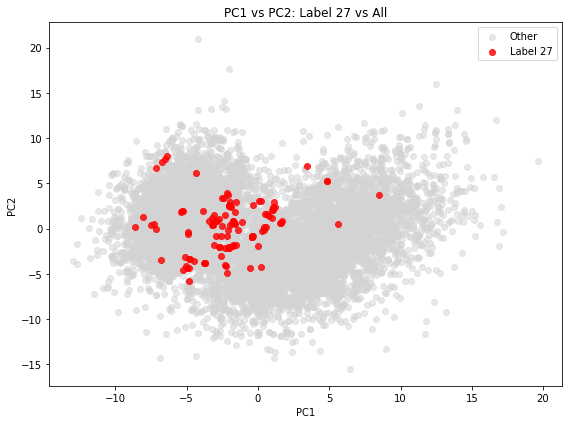

In [135]:
# Visualise smote
plot_label_vs_all(tomek,labels)